# Cognifyz Business Analytics Internship
## Investor Survey Analysis

This project analyzes the 40-response investor survey supplied with the internship materials. It addresses all ten tasks in the project brief, from data overview through correlation analysis.

**Files:** `Data_set 2 - Copy.csv` is the source data. The notebook writes a duplicate-free `cleaned_data.csv` in the project folder.

**Scope:** The survey is a small descriptive sample. Findings describe these respondents and should not be treated as representative of a broader population or as investment advice.

## Setup and data quality
Load the source file from the notebook folder, inspect its structure and missing values, remove exact duplicate records, and save the cleaned data.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("Data_set 2 - Copy.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Place {DATA_FILE.name} beside this notebook.")

raw_df = pd.read_csv(DATA_FILE)
print(f"Source shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
print(f"Exact duplicate rows: {raw_df.duplicated().sum()}")
print(f"Missing values: {raw_df.isna().sum().sum()}")
df = raw_df.drop_duplicates().copy()
clean_path = Path("cleaned_data.csv")
df.to_csv(clean_path, index=False)
print(f"Cleaned shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Saved cleaned data to: {clean_path.resolve()}")

Source shape: 40 rows x 24 columns
Exact duplicate rows: 0
Missing values: 0
Cleaned shape: 40 rows x 24 columns
Saved cleaned data to: C:\Users\LENOVO\OneDrive\Documents\Data analytics\Internship\Cognifyz\cleaned_data.csv


## Task 1 - Data overview
The survey contains demographic data, investment preference ratings, selected investment avenues, objectives, reasons, durations, return expectations, and information sources.

In [2]:
display(df.head())
df.info()
display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=True)
}))

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   gender                             40 non-null     str  
 1   age                                40 non-null     int64
 2   Investment_Avenues                 40 non-null     str  
 3   Mutual_Funds                       40 non-null     int64
 4   Equity_Market                      40 non-null     int64
 5   Debentures                         40 non-null     int64
 6   Government_Bonds                   40 non-null     int64
 7   Fixed_Deposits                     40 non-null     int64
 8   PPF                                40 non-null     int64
 9   Gold                               40 non-null     int64
 10  Stock_Marktet                      40 non-null     str  
 11  Factor                             40 non-null     str  
 12  Objective                          

,gender,age,Investment_Avenues,Mutual_Funds,Equity_Market,Debentures,Government_Bonds,Fixed_Deposits,PPF,Gold,Stock_Marktet,Factor,Objective,Purpose,Duration,Invest_Monitor,Expect,Avenue,What are your savings objectives?,Reason_Equity,Reason_Mutual,Reason_Bonds,Reason_FD,Source
0,Female,34,Yes,1,2,5,3,7,6,4,Yes,Returns,Capital Appreciation,Wealth Creation,1-3 years,Monthly,20%-30%,Mutual Fund,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Fixed Returns,Newspapers and Magazines
1,Female,23,Yes,4,3,2,1,5,6,7,No,Locking Period,Capital Appreciation,Wealth Creation,More than 5 years,Weekly,20%-30%,Mutual Fund,Health Care,Dividend,Better Returns,Safe Investment,High Interest Rates,Financial Consultants
2,Male,30,Yes,3,6,4,2,5,1,7,Yes,Returns,Capital Appreciation,Wealth Creation,3-5 years,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Tax Benefits,Assured Returns,Fixed Returns,Television
3,Male,22,Yes,2,1,3,7,6,4,5,Yes,Returns,Income,Wealth Creation,Less than 1 year,Daily,10%-20%,Equity,Retirement Plan,Dividend,Fund Diversification,Tax Incentives,High Interest Rates,Internet
4,Female,24,No,2,1,3,6,4,5,7,No,Returns,Income,Wealth Creation,Less than 1 year,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Risk Free,Internet


,data_type,non_null,missing,unique
gender,str,40,0,2
age,int64,40,0,14
Investment_Avenues,str,40,0,2
Mutual_Funds,int64,40,0,6
Equity_Market,int64,40,0,6
Debentures,int64,40,0,7
Government_Bonds,int64,40,0,7
Fixed_Deposits,int64,40,0,7
PPF,int64,40,0,6
Gold,int64,40,0,6


## Task 2 - Gender distribution
The chart shows the number and share of respondents in each gender category.

,respondents,share_percent
gender,,
Female,15,37.5
Male,25,62.5


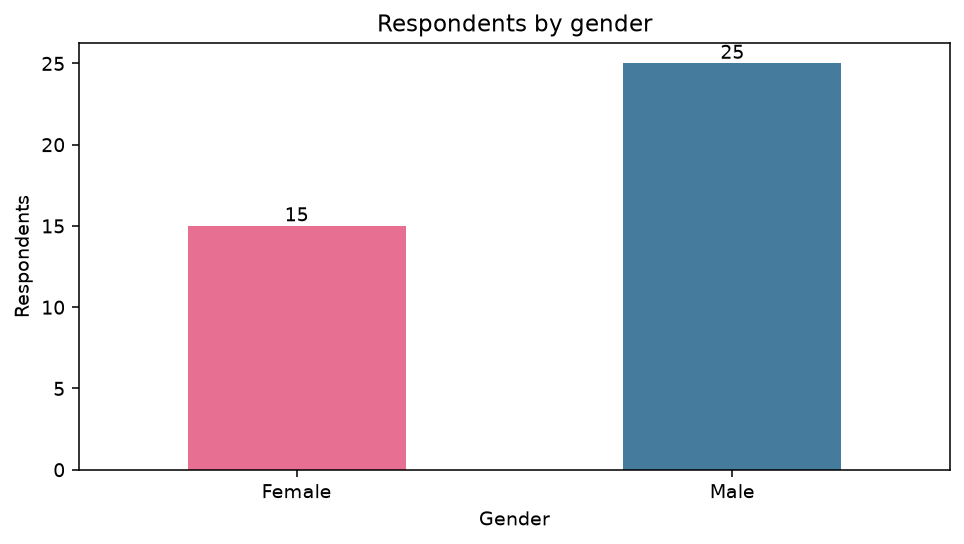

In [3]:
gender_counts = df["gender"].value_counts().reindex(["Female", "Male"], fill_value=0)
display(pd.DataFrame({"respondents": gender_counts, "share_percent": (gender_counts / len(df) * 100).round(1)}))
ax = gender_counts.plot(kind="bar", color=["#e76f91", "#457b9d"], figsize=(7, 4))
ax.set(title="Respondents by gender", xlabel="Gender", ylabel="Respondents")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Task 3 - Descriptive statistics
Numeric fields include age and seven 1-7 investment preference ratings. The rating columns represent survey scores, not monetary amounts.

In [4]:
numeric_cols = df.select_dtypes(include="number").columns
desc = df[numeric_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
desc = desc.rename(columns={"count":"Count", "mean":"Mean", "median":"Median", "std":"Std. deviation", "min":"Minimum", "max":"Maximum"}).round(2)
display(desc)

,Count,Mean,Median,Std. deviation,Minimum,Maximum
age,40.0,27.80,27.0,3.56,21.0,35.0
Mutual_Funds,40.0,2.55,2.0,1.20,1.0,7.0
Equity_Market,40.0,3.48,4.0,1.13,1.0,6.0
Debentures,40.0,5.75,6.5,1.68,1.0,7.0
Government_Bonds,40.0,4.65,5.0,1.37,1.0,7.0
Fixed_Deposits,40.0,3.58,3.5,1.80,1.0,7.0
PPF,40.0,2.02,1.0,1.61,1.0,6.0
Gold,40.0,5.98,6.0,1.14,2.0,7.0


## Task 4 - Most preferred investment avenue
Preference is measured by the respondents' selected `Avenue` category.

Most selected avenue: Mutual Fund (18 of 40 respondents, 45.0%).


,respondents,share_percent
Avenue,,
Mutual Fund,18,45.0
Equity,10,25.0
Fixed Deposits,9,22.5
Public Provident Fund,3,7.5


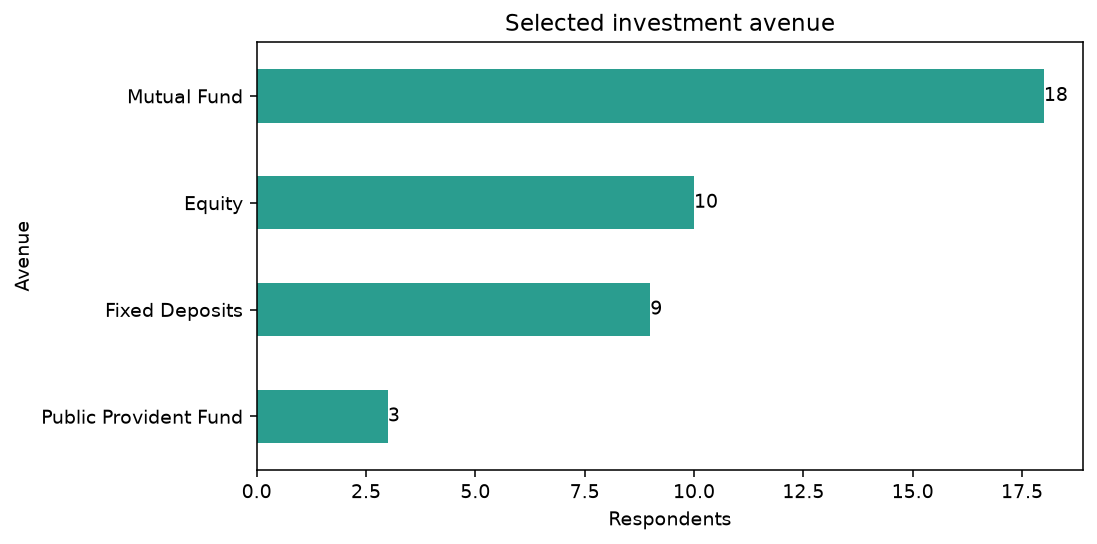

In [5]:
avenue_counts = df["Avenue"].value_counts()
display(pd.DataFrame({"respondents": avenue_counts, "share_percent": (avenue_counts / len(df) * 100).round(1)}))
ax = avenue_counts.sort_values().plot(kind="barh", color="#2a9d8f", figsize=(8, 4))
ax.set(title="Selected investment avenue", xlabel="Respondents", ylabel="Avenue")
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()
print(f"Most selected avenue: {avenue_counts.idxmax()} ({avenue_counts.max()} of {len(df)} respondents, {avenue_counts.max()/len(df):.1%}).")

## Task 5 - Reasons for investment
The questionnaire records reasons separately for equity, mutual funds, bonds, and fixed deposits. To summarize common themes, responses are stacked across these four reason fields. Each participant can therefore contribute up to four mentions; counts are mentions rather than unique participants.

Most frequent reason overall: Capital Appreciation


,mentions,share_of_mentions_percent
reason,,
Capital Appreciation,30,18.8
Assured Returns,26,16.2
Better Returns,24,15.0
Risk Free,19,11.9
Fixed Returns,18,11.2
Fund Diversification,13,8.1
Safe Investment,13,8.1
Dividend,8,5.0
Tax Benefits,3,1.9


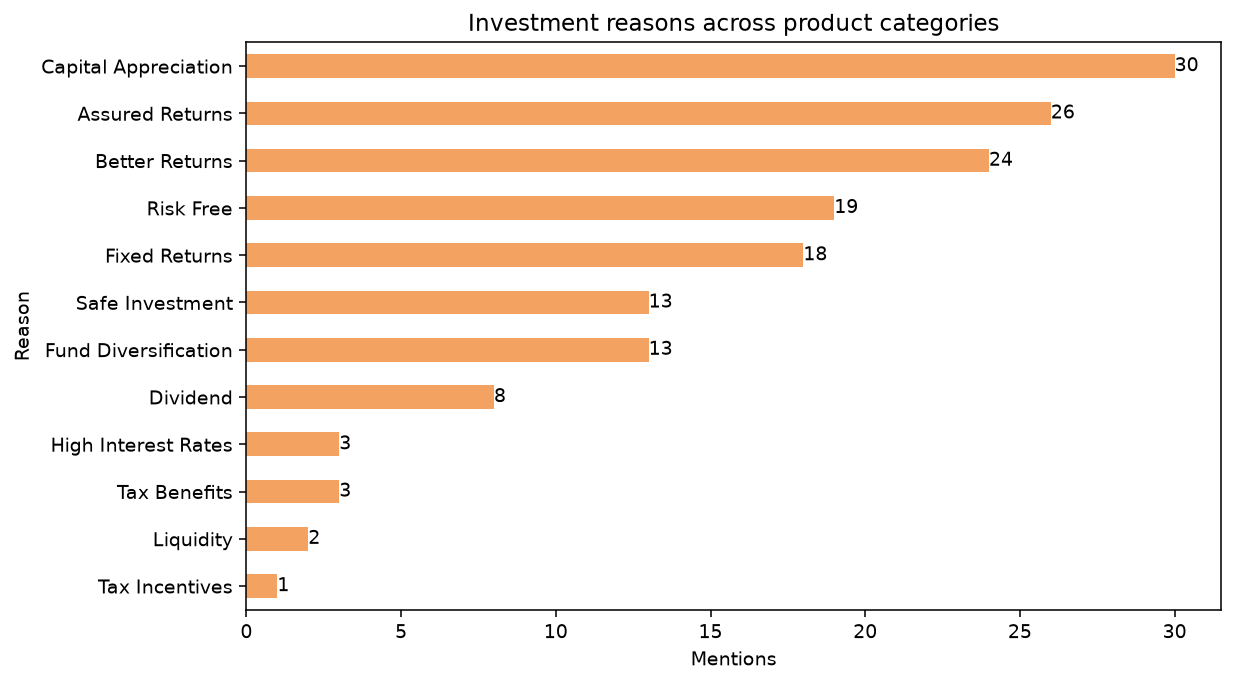

In [6]:
reason_cols = ["Reason_Equity", "Reason_Mutual", "Reason_Bonds", "Reason_FD"]
reason_long = df[reason_cols].melt(var_name="investment_type", value_name="reason").dropna()
reason_counts = reason_long["reason"].value_counts()
display(pd.DataFrame({"mentions": reason_counts, "share_of_mentions_percent": (reason_counts / len(reason_long) * 100).round(1)}))
ax = reason_counts.sort_values().plot(kind="barh", color="#f4a261", figsize=(9, 5))
ax.set(title="Investment reasons across product categories", xlabel="Mentions", ylabel="Reason")
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()
print("Most frequent reason overall:", reason_counts.idxmax())

## Task 6 - Savings objectives
List the reported objectives and their frequency in the sample.

,respondents,share_percent
What are your savings objectives?,,
Retirement Plan,24,60.0
Health Care,13,32.5
Education,3,7.5


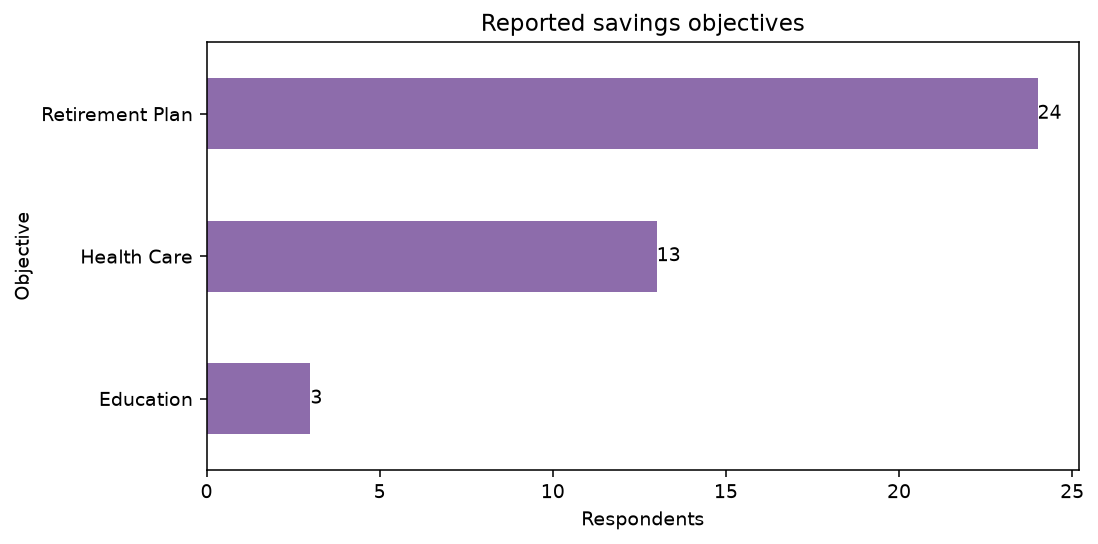

In [7]:
objective_counts = df["What are your savings objectives?"].value_counts()
display(pd.DataFrame({"respondents": objective_counts, "share_percent": (objective_counts / len(df) * 100).round(1)}))
ax = objective_counts.sort_values().plot(kind="barh", color="#8d6cab", figsize=(8, 4))
ax.set(title="Reported savings objectives", xlabel="Respondents", ylabel="Objective")
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()

## Task 7 - Common information sources
Compare how respondents say they receive investment information.

,respondents,share_percent
Source,,
Financial Consultants,16,40.0
Newspapers and Magazines,14,35.0
Television,6,15.0
Internet,4,10.0


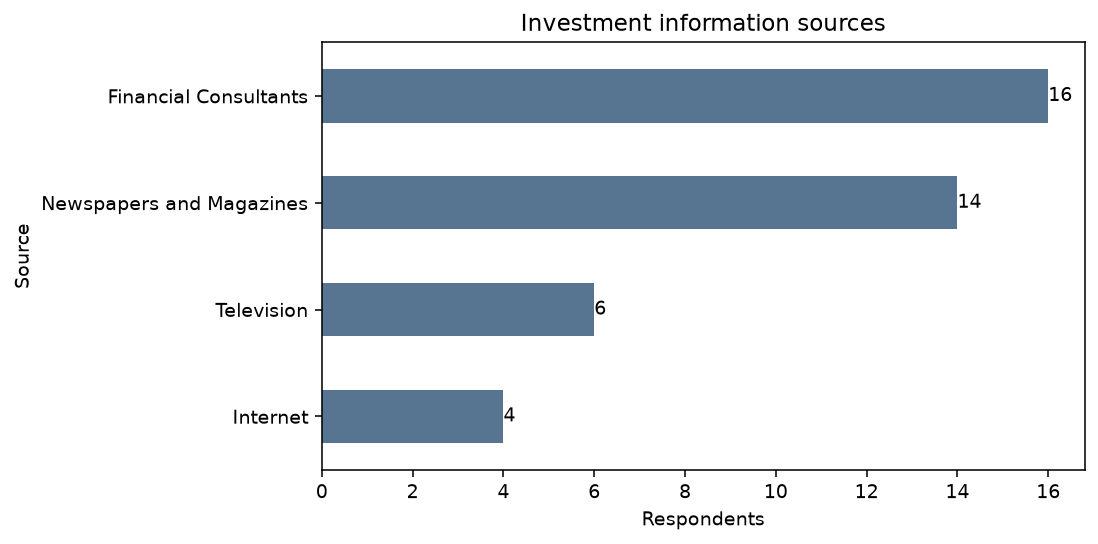

In [8]:
source_counts = df["Source"].value_counts()
display(pd.DataFrame({"respondents": source_counts, "share_percent": (source_counts / len(df) * 100).round(1)}))
ax = source_counts.sort_values().plot(kind="barh", color="#577590", figsize=(8, 4))
ax.set(title="Investment information sources", xlabel="Respondents", ylabel="Source")
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()

## Task 8 - Average investment duration
Duration is reported in ranges rather than exact years. For an approximate average, ranges are represented by their midpoints: less than 1 year = 0.5, 1-3 years = 2, 3-5 years = 4, and more than 5 years = 6. The last category is assigned 6 years as an explicit approximation. This is an estimate, not an exact mean duration.

Approximate mean investment duration: 2.98 years (midpoint method).


,respondents,assigned_midpoint_years
Duration,,
Less than 1 year,2,0.5
1-3 years,18,2.0
3-5 years,19,4.0
More than 5 years,1,6.0


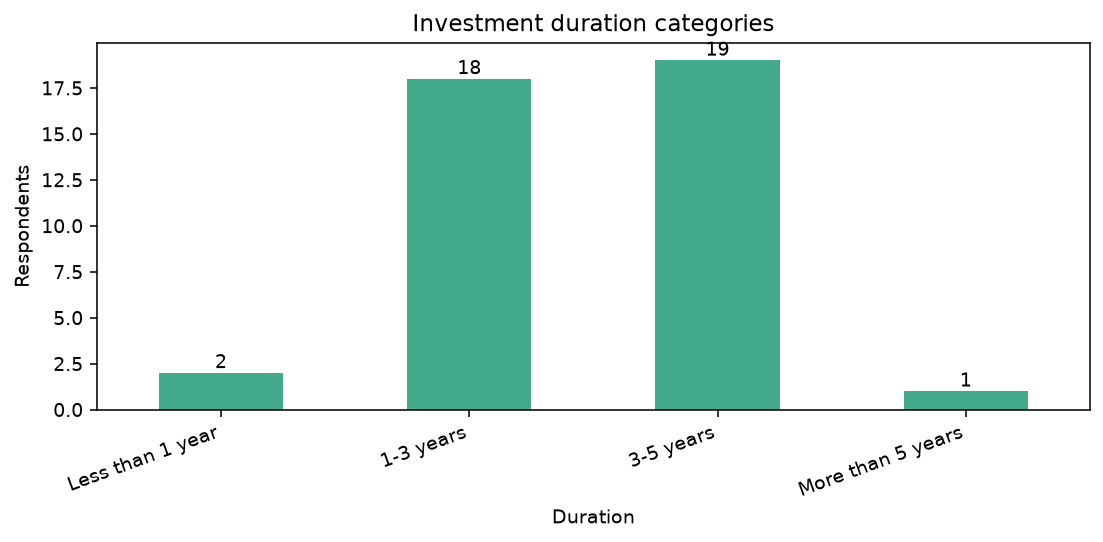

In [9]:
duration_midpoints = {"Less than 1 year": 0.5, "1-3 years": 2, "3-5 years": 4, "More than 5 years": 6}
duration_counts = df["Duration"].value_counts()
duration_table = pd.DataFrame({"respondents": duration_counts}).reindex(duration_midpoints).fillna(0).astype({"respondents": int})
duration_table["assigned_midpoint_years"] = duration_table.index.map(duration_midpoints)
display(duration_table)
mean_duration = df["Duration"].map(duration_midpoints).mean()
print(f"Approximate mean investment duration: {mean_duration:.2f} years (midpoint method).")
ax = duration_table["respondents"].plot(kind="bar", color="#43aa8b", figsize=(8, 4))
ax.set(title="Investment duration categories", xlabel="Duration", ylabel="Respondents")
ax.bar_label(ax.containers[0]); plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## Task 9 - Expectations from investments
Return expectations are reported in percentage bands. The frequency table preserves the original categories.

,respondents,share_percent
Expect,,
10%-20%,3,7.5
20%-30%,32,80.0
30%-40%,5,12.5


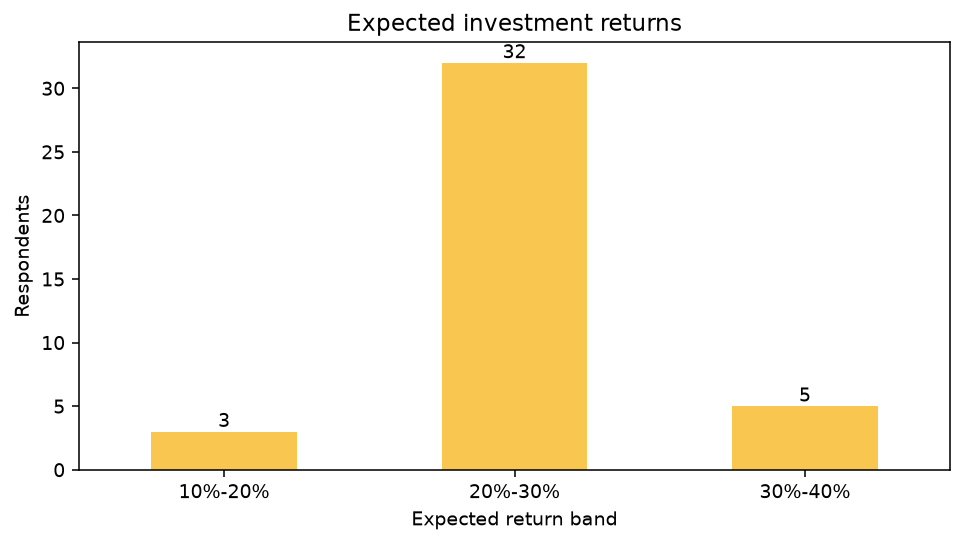

In [10]:
expect_counts = df["Expect"].value_counts()
expect_order = ["10%-20%", "20%-30%", "30%-40%"]
expect_counts = expect_counts.reindex(expect_order).dropna().astype(int)
display(pd.DataFrame({"respondents": expect_counts, "share_percent": (expect_counts / len(df) * 100).round(1)}))
ax = expect_counts.plot(kind="bar", color="#f9c74f", figsize=(7, 4))
ax.set(title="Expected investment returns", xlabel="Expected return band", ylabel="Respondents")
ax.bar_label(ax.containers[0]); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Task 10 - Correlation analysis
To include the categorical duration and return bands, the analysis assigns duration midpoints as above and return-band midpoints of 15%, 25%, and 35%. Pearson correlations on these coded values are exploratory and depend on those assumptions. The heatmap also includes the 1-7 preference ratings; it should not be read as evidence of causation.

Age vs duration midpoint correlation: 0.05
Age vs expected-return midpoint correlation: -0.09


,Age,Duration midpoint (years),Expected return midpoint (%),Mutual Funds,Equity Market,Debentures,Government Bonds,Fixed Deposits,PPF,Gold
Age,1.00,0.05,-0.09,-0.12,0.25,0.33,-0.09,-0.03,-0.26,-0.06
Duration midpoint (years),0.05,1.00,0.26,0.18,0.47,0.03,-0.29,-0.19,-0.19,0.20
Expected return midpoint (%),-0.09,0.26,1.00,0.04,0.10,0.46,0.24,-0.42,-0.11,-0.30
Mutual Funds,-0.12,0.18,0.04,1.00,0.33,-0.35,-0.11,-0.03,-0.19,-0.40
Equity Market,0.25,0.47,0.10,0.33,1.00,-0.02,-0.24,-0.24,-0.43,-0.05
Debentures,0.33,0.03,0.46,-0.35,-0.02,1.00,0.43,-0.47,-0.51,-0.14
Government Bonds,-0.09,-0.29,0.24,-0.11,-0.24,0.43,1.00,-0.53,-0.24,-0.30
Fixed Deposits,-0.03,-0.19,-0.42,-0.03,-0.24,-0.47,-0.53,1.00,0.08,-0.09
PPF,-0.26,-0.19,-0.11,-0.19,-0.43,-0.51,-0.24,0.08,1.00,0.13
Gold,-0.06,0.20,-0.30,-0.40,-0.05,-0.14,-0.30,-0.09,0.13,1.00


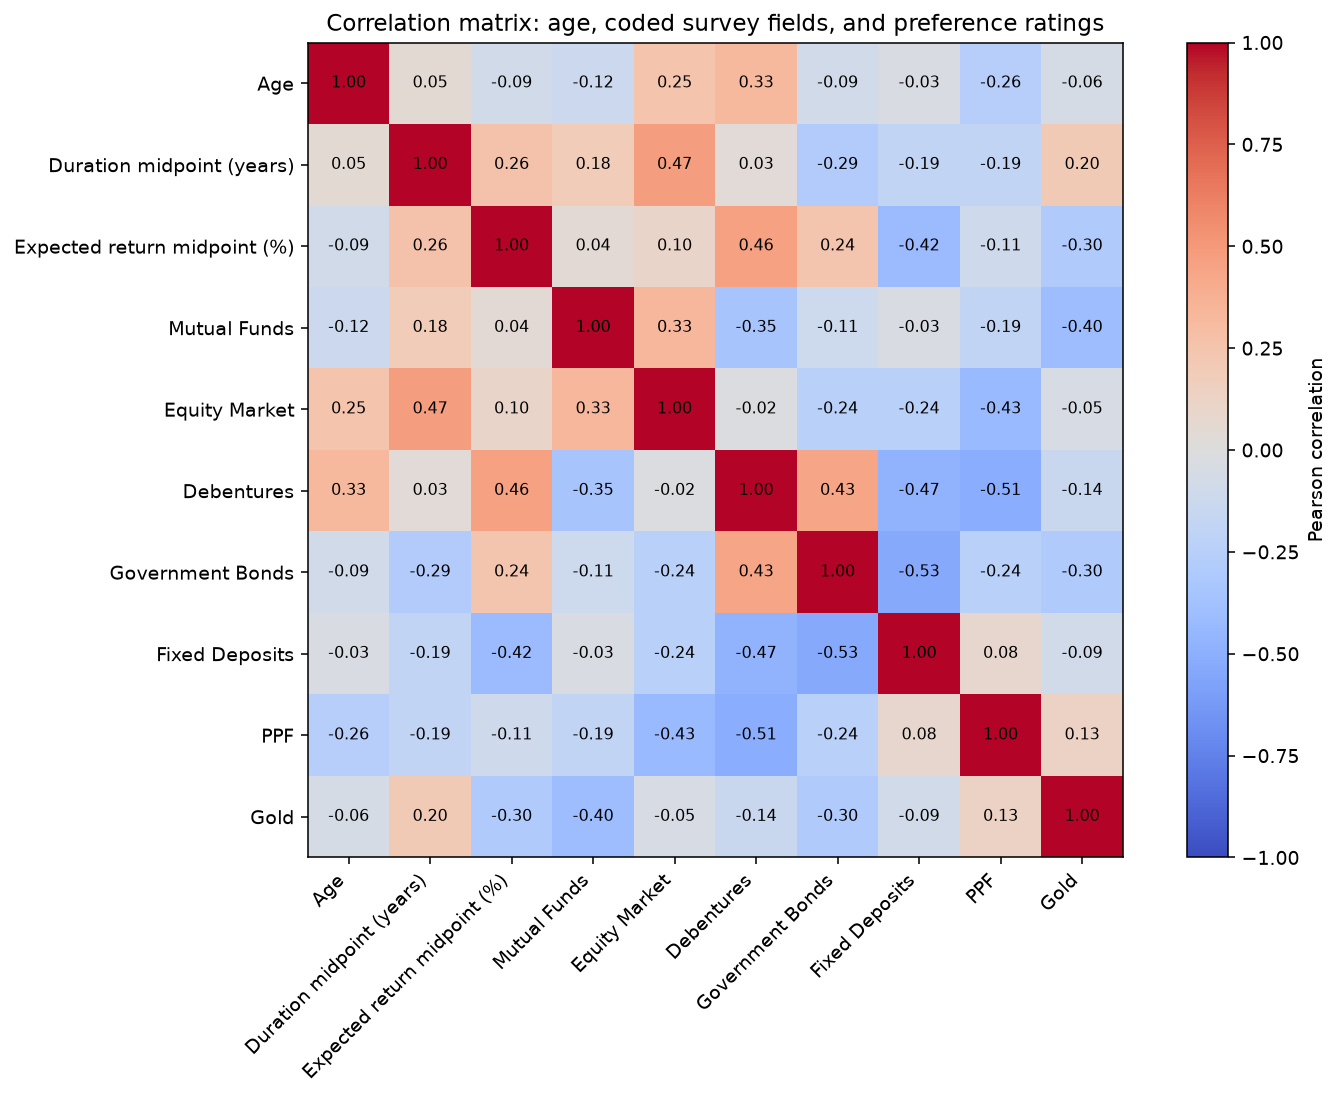

In [11]:
duration_years = df["Duration"].map(duration_midpoints)
return_midpoints = {"10%-20%": 15, "20%-30%": 25, "30%-40%": 35}
expected_return_midpoint = df["Expect"].map(return_midpoints)
correlation_data = pd.DataFrame({
    "Age": df["age"],
    "Duration midpoint (years)": duration_years,
    "Expected return midpoint (%)": expected_return_midpoint,
    **{col.replace("_", " "): df[col] for col in ["Mutual_Funds", "Equity_Market", "Debentures", "Government_Bonds", "Fixed_Deposits", "PPF", "Gold"]}
})
corr = correlation_data.corr(numeric_only=True)
display(corr.round(2))
plt.figure(figsize=(11, 8))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation matrix: age, coded survey fields, and preference ratings")
plt.tight_layout(); plt.show()
print("Age vs duration midpoint correlation:", round(corr.loc["Age", "Duration midpoint (years)"], 2))
print("Age vs expected-return midpoint correlation:", round(corr.loc["Age", "Expected return midpoint (%)"], 2))

## Findings summary
- The cleaned sample contains 40 responses across 24 columns, with no missing values and no exact duplicate rows.
- The largest gender group is male (25 respondents, 62.5%).
- Mutual funds are the most frequently selected avenue (18 respondents, 45%).
- Across the four product-specific reason fields, capital appreciation is the most common reason mention (30 of 160 mentions), followed by assured returns (26) and better returns (24); counts combine categories and can include multiple mentions per person.
- Retirement planning is the most common savings objective (24 respondents, 60%). Financial consultants (16) and newspapers/magazines (14) are the most reported information sources.
- Most participants report a 3-5 year duration (19) or 1-3 year duration (18). The midpoint estimate of average duration is 2.98 years using the assumptions above.
- The most common expected return band is 20%-30% (32 respondents, 80%).
- Age has near-zero linear correlation with duration midpoint (r = 0.05) and expected-return midpoint (r = -0.09) under the coding assumptions. Correlations are descriptive associations in this small sample; the categorical midpoint coding is approximate, and no causal interpretation is warranted.

## Interpretation and recommendations

**What the sample suggests.** Respondents in this 40-person sample lean toward a medium-term investment horizon: 37 of 40 (92.5%) report 1–5 years, while 32 (80%) expect 20%–30% returns. Mutual funds lead selected avenues (45%), and retirement is the leading savings objective (60%). Together, these responses suggest a sample that values growth and retirement preparation while generally planning over several years. The 20%–30% return expectation is an expectation reported by respondents; it is not a forecast or a guarantee.

**How to read the reasons.** Respondents most often cite capital appreciation for equity (30), better returns for mutual funds (24), assured returns for bonds (26), and risk-free returns for fixed deposits (19). This points to different perceived roles across products: growth for equity and mutual funds, and certainty for bonds and deposits. These are stated reasons, not measured risk or realized performance.

**Practical recommendations.** Make investor education compare potential return with risk, liquidity, and time horizon; set realistic expectations around return bands; and explain diversification when discussing mutual funds. Since financial consultants (16) and newspapers/magazines (14) are the most reported information sources, clear explainers through those channels may reach many respondents in a similar audience.

**Limits.** This is a descriptive survey of 40 respondents, not a representative population estimate. Counts describe this sample only. Duration and expected-return correlations use category midpoints as approximations, and the near-zero correlations with age (r = 0.05 and r = -0.09) do not support a meaningful linear relationship in this sample. The survey does not establish causation, actual returns, investment suitability, or the reasons behind group differences.
